# Regridding: ERA5-Land yearly precipitation on the RhiresY grid

This example illustrates {func}`~grid_process.grid_interp.interp2grid` with three methods:

- `nearest`: value of the nearest source grid point;
- `idw`: inverse distance weighting of the `k` nearest grid points, with weights `d^(-weight_power)`;
- `linear`: bilinear interpolation, since the source grid is regular.

The 2024 precipitation total of the ERA5-Land reanalysis (regular 0.1° grid, about 9 km) is regridded
to the 1 km grid of RhiresY, the MeteoSwiss yearly precipitation analysis based on rain gauges, in the
Swiss LV95 coordinate system. RhiresY 2024 is shown alongside as a reference.

Running this notebook needs a free account on the
[Copernicus Climate Data Store](https://cds.climate.copernicus.eu): your API token in `~/.cdsapirc`
and the licence of the ERA5-Land dataset accepted once on its download page.

*Data: contains modified Copernicus Climate Change Service information 2026, ERA5-Land monthly averaged
data (DOI: 10.24381/cds.68d2bb30), CC BY 4.0. MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss.
Country borders: Natural Earth.*

In [1]:
import time
import timeit
from collections.abc import Callable
from functools import partial
from typing import Any

# import pyproj before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import pyproj  # noqa: F401  # pylint: disable=unused-import
import cartopy.crs as ccrs
import earthkit.data as ekd
import earthkit.plots as ekp
import geopandas as gpd
import numpy as np
import pandas as pd
import xarray as xr

import grid_process.grid_interp as gri
import grid_process.units_conv as uconv
from grid_process import data_model as dm

METHODS: dict[str, dict[str, Any]] = {
    "nearest": {"method": "nearest"},
    "idw": {"method": "idw", "k": 4, "weight_power": 2},
    "linear": {"method": "linear"},
}
YEAR = 2024

## Destination grid and reference

The RhiresY file is a CF-compliant NetCDF file: `grid_process` finds the `E`/`N` coordinates from their
`standard_name` and the LV95 projection from the grid mapping variable, so the dataset can be used as
the destination grid as is. RhiresY has no value outside its analysis domain (Switzerland and some
border areas).

In [2]:
RHIRES_URL = (
    "https://data.geo.admin.ch/ch.meteoschweiz.ogd-surface-derived-grid/archive-ch/"
    "ogd-surface-derived-grid-archive.rhiresy_ch01r.swiss.lv95_20240101000000_20240101000000.nc"
)
# time units "years since ..." cannot be decoded by xarray and are not needed here
dst_grid = ekd.from_source("url", RHIRES_URL).to_xarray(decode_times=False).squeeze("time", drop=True)
rhires = dst_grid["RhiresY"]
dst_grid

<xarray.Dataset> Size: 1MB
Dimensions:                 (N: 240, E: 370)
Coordinates:
  * N                       (N) float64 2kB 1.064e+06 1.066e+06 ... 1.304e+06
  * E                       (E) float64 3kB 2.474e+06 2.476e+06 ... 2.844e+06
    lon                     (N, E) float32 355kB ...
    lat                     (N, E) float32 355kB ...
Data variables:
    RhiresY                 (N, E) float32 355kB ...
    swiss_lv95_coordinates  float64 8B ...
Attributes:
    Conventions:  CF-1.8
    institution:  Data produced at Federal Office of Meteorology and Climatol...
    References:   Information on the data is available at\nhttps://www.meteos...
    title:        Spatial Climate Analyses Dataset of MeteoSwiss (RhiresY)
    history:      2025-01-24 18:12:45 - generated by gridmch 7.31.0

## Source data

ERA5-Land monthly means are retrieved from the Climate Data Store for a box around Switzerland with a
wide margin (`area` = North, West, South, East). Monthly means of accumulated variables are daily
totals in metres, so the yearly total is the sum over the months of the daily total times the number
of days in the month.

In [3]:
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": ["total_precipitation"],
    "year": [str(YEAR)],
    "month": [f"{month:02d}" for month in range(1, 13)],
    "time": ["00:00"],
    "area": [49.0, 4.5, 44.5, 12.0],
    "data_format": "netcdf",
    "download_format": "unarchived",
}
era5 = ekd.from_source("cds", "reanalysis-era5-land-monthly-means", request).to_xarray()

tp = era5["tp"]
days = tp["valid_time"].dt.days_in_month
total = (tp * days).sum("valid_time", skipna=False).assign_attrs(units="m")  # daily totals [m] × days
ds = uconv.ds_to(total.reset_coords(drop=True).to_dataset(name="precipitation"), "mm")
ds["precipitation"].attrs["long_name"] = f"precipitation total {YEAR}"
ds

<xarray.Dataset> Size: 29kB
Dimensions:        (latitude: 46, longitude: 76)
Coordinates:
  * latitude       (latitude) float64 368B 49.0 48.9 48.8 ... 44.7 44.6 44.5
  * longitude      (longitude) float64 608B 4.5 4.6 4.7 4.8 ... 11.8 11.9 12.0
Data variables:
    precipitation  (latitude, longitude) float64 28kB 983.7 991.6 ... 832.0

## Interpolation

Each method is called once, and the duration of this first call is kept for the benchmark below. The
outputs are masked outside the RhiresY analysis domain. On a regular grid with 1D coordinates, `nearest` and `linear` use xarray's interpolation by default (`try_reg=True`), which is efficient for large grids but may be slower for small grids with many other dimensions. They are also run through the generic path (`try_reg=False`) for comparison.

In [4]:
def with_try_reg(methods: dict[str, dict[str, Any]], data: xr.Dataset) -> dict[str, dict[str, Any]]:
    """On a grid with 1D spatial coordinates, 'nearest' and 'linear' use xarray's interpolation by default
    (try_reg=True): add the generic path (try_reg=False) to compare both."""
    regular = len(dm.get_spatial_dims(data)) == 2
    expanded: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        if regular and kw["method"] in ("nearest", "linear"):
            expanded[method] = kw | {"try_reg": True}
            expanded[f"{method} (try_reg=False)"] = kw | {"try_reg": False}
        else:
            expanded[method] = kw
    return expanded


runs = with_try_reg(METHODS, ds)
results: dict[str, xr.DataArray] = {}
first_call: dict[str, float] = {}
for label, kwargs in runs.items():
    t0 = time.perf_counter()
    out = gri.interp2grid(ds, dst_grid, **kwargs)
    first_call[label] = time.perf_counter() - t0
    results[label] = out["precipitation"].where(rhires.notnull())
for label in METHODS:
    if f"{label} (try_reg=False)" in results:
        diff = abs(results[label] - results[f"{label} (try_reg=False)"])
        print(
            f"{label}, try_reg=True vs. False: mean abs. difference {diff.mean().item():.3g} mm,"
            f" max. {diff.max().item():.3g} mm"
        )
results["linear"]

nearest, try_reg=True vs. False: mean abs. difference 0 mm, max. 0 mm
linear, try_reg=True vs. False: mean abs. difference 2.5 mm, max. 47.5 mm


<xarray.DataArray 'precipitation' (N: 240, E: 370)> Size: 710kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(240, 370))
Coordinates:
  * N        (N) float64 2kB 1.064e+06 1.066e+06 ... 1.302e+06 1.304e+06
  * E        (E) float64 3kB 2.474e+06 2.476e+06 ... 2.842e+06 2.844e+06
    lon      (N, E) float32 355kB 5.827 5.84 5.853 5.865 ... 10.67 10.68 10.69
    lat      (N, E) float32 355kB 45.72 45.72 45.72 45.72 ... 47.84 47.84 47.84
Attributes: (12/30)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3496
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_shortName:                           tp
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    units:                                    mm
    GRIB_surface:                             0.0
    long_name:                                precipitation total 2024

## Visual comparison

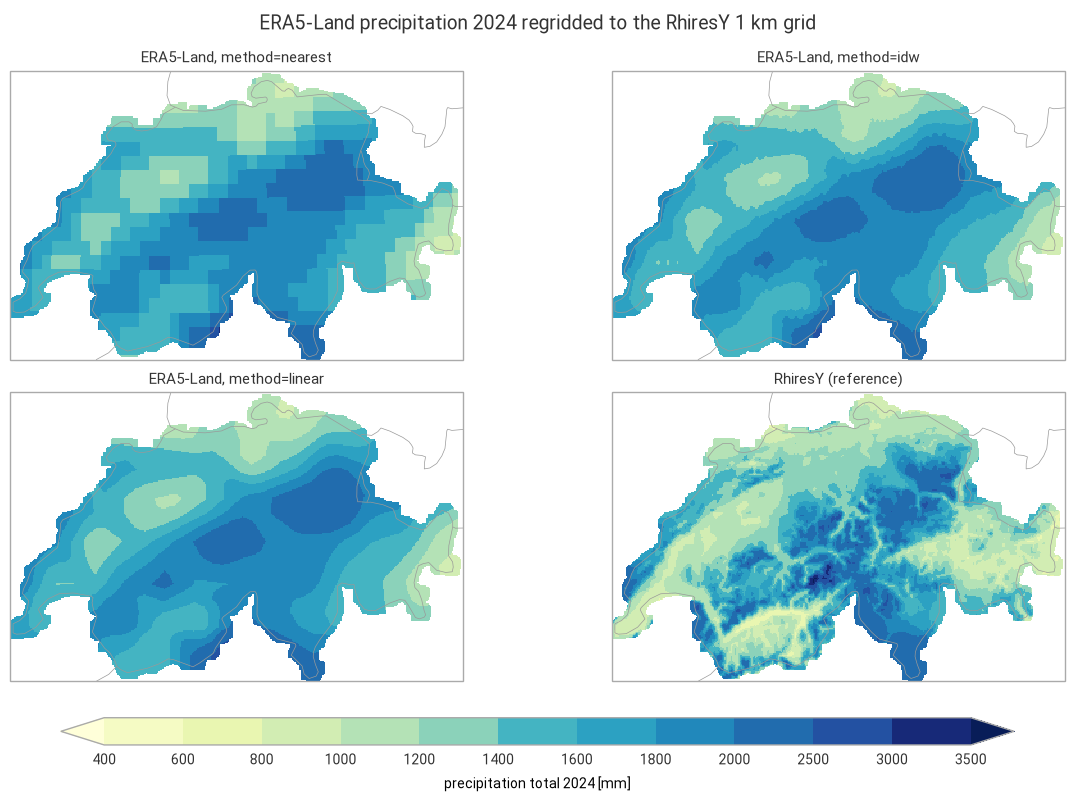

In [5]:
lv95 = ccrs.epsg(2056)
style = ekp.styles.Style(
    levels=[400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000, 2500, 3000, 3500],
    colors="YlGnBu",
    extend="both",
    units="mm",
)
panels = {f"ERA5-Land, method={label}": results[label] for label in METHODS} | {"RhiresY (reference)": rhires}

fig = ekp.Figure(rows=2, columns=2, figsize=(12, 7.5), crs=lv95)
for i, (title, field) in enumerate(panels.items()):
    subplot = fig.add_map(i // 2, i % 2)
    subplot.pcolormesh(field.values, x=field.E.values, y=field.N.values, style=style, transform=lv95)
    subplot.title(title)
fig.borders()
fig.legend(label=f"precipitation total {YEAR} [mm]")
fig.title(f"ERA5-Land precipitation {YEAR} regridded to the RhiresY 1 km grid")
fig.show()

## Performance benchmark

The first call includes building the neighbour search structures and reprojecting the coordinates,
which `grid_process` caches. Subsequent calls on the same grids (e.g. for other variables or years)
reuse them: their runtime is the mean ± standard deviation over 5 repetitions.

In [6]:
def benchmark(
    func: Callable[..., xr.Dataset],
    data: xr.Dataset,
    target: gpd.GeoDataFrame | xr.Dataset,
    methods: dict[str, dict[str, Any]],
    first_call_times: dict[str, float],
    repeat: int = 5,
) -> pd.DataFrame:
    """Runtime of the first call and mean ± standard deviation of the subsequent calls of each method."""
    rows: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        times = np.array(timeit.repeat(partial(func, data, target, **kw), number=1, repeat=repeat))
        rows[method] = {
            "first call [s]": f"{first_call_times[method]:.3f}",
            "subsequent calls [s]": f"{times.mean():.3f} ± {times.std():.3f}",
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("method")


print(f"{ds.latitude.size} × {ds.longitude.size} source grid points -> {dst_grid.N.size} × {dst_grid.E.size} cells")
benchmark(gri.interp2grid, ds, dst_grid, runs, first_call)

46 × 76 source grid points -> 240 × 370 cells


,first call [s],subsequent calls [s]
method,,
nearest,0.060,0.028 ± 0.001
nearest (try_reg=False),0.021,0.010 ± 0.000
idw,0.035,0.017 ± 0.000
linear,0.027,0.026 ± 0.001
linear (try_reg=False),0.027,0.025 ± 0.000


## Takeaways

- `nearest` shows the 9 km ERA5-Land grid boxes on the 1 km grid. `idw` and `linear` give smooth fields
  that are nearly identical here: with `k=4` and `weight_power=2`, `idw` weights the corners of the source
  grid box much like bilinear interpolation.
- No method can add detail that the source grid does not resolve: compared with RhiresY, the regridded
  fields miss the dry inner-alpine valleys (Valais, Engadine) and the wettest crests, and ERA5-Land is
  wetter than RhiresY over most of the Plateau.
- On the regular ERA5-Land grid, `nearest` gives the same values with the regular path (`try_reg=True`,
  xarray's interpolation) and with the generic path (`try_reg=False`). `linear` differs by a few mm on
  average and up to about 50 mm, since the regular path is bilinear and the generic path interpolates on a
  triangulation of the source grid points.
- For a single small field like this one, every method takes a few hundredths of a second, and the
  generic path of `nearest` is faster than the regular one.